In [1]:
%pip install -U ucimlrepo pandas numpy scikit-learn matplotlib gradio flask openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
student_data = fetch_ucirepo(id=320)

student_features = student_data.data.features.copy()
student_targets = student_data.data.targets.copy()

student_df = pd.concat(
    [student_features, student_targets],
    axis=1
)

print("Student Performance dataset loaded successfully!")
print("Dataset shape:", student_df.shape)

display(student_df.head())

Student Performance dataset loaded successfully!
Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [4]:
energy_data = fetch_ucirepo(id=242)

energy_features = energy_data.data.features.copy()
energy_targets = energy_data.data.targets.copy()

energy_df = pd.concat(
    [energy_features, energy_targets],
    axis=1
)

print("Energy Efficiency dataset loaded successfully!")
print("Dataset shape:", energy_df.shape)

display(energy_df.head())

Energy Efficiency dataset loaded successfully!
Dataset shape: (768, 10)


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [5]:
print("Student columns:")
print(student_df.columns.tolist())

print("\nEnergy columns:")
print(energy_df.columns.tolist())

Student columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Energy columns:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2']


In [6]:
print("STUDENT DATA")
print("Missing values:", student_df.isnull().sum().sum())
print("Duplicate rows:", student_df.duplicated().sum())
print(student_df.dtypes)

print("\nENERGY DATA")
print("Missing values:", energy_df.isnull().sum().sum())
print("Duplicate rows:", energy_df.duplicated().sum())
print(energy_df.dtypes)

STUDENT DATA
Missing values: 0
Duplicate rows: 0
school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

ENERGY DATA
Missing values: 0
Duplicate rows: 0
X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X6      int64
X7    float64
X8      int64
Y1    float64
Y2    float64
dtype: object


In [7]:
student_input_columns = [
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

student_target_column = "G3"

energy_input_columns = [
    "X1", "X2", "X3", "X4",
    "X5", "X6", "X7", "X8"
]

energy_target_column = "Y1"

X_student = student_df[student_input_columns].copy()
y_student = student_df[student_target_column].copy()

X_energy = energy_df[energy_input_columns].copy()
y_energy = energy_df[energy_target_column].copy()

print("Student input features:", X_student.columns.tolist())
print("Student target:", student_target_column)

print("\nEnergy input features:", X_energy.columns.tolist())
print("Energy target:", energy_target_column)

Student input features: ['studytime', 'failures', 'absences', 'G1', 'G2']
Student target: G3

Energy input features: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
Energy target: Y1


In [8]:
X_student_train, X_student_test, y_student_train, y_student_test = (
    train_test_split(
        X_student,
        y_student,
        test_size=0.20,
        random_state=42
    )
)

X_energy_train, X_energy_test, y_energy_train, y_energy_test = (
    train_test_split(
        X_energy,
        y_energy,
        test_size=0.20,
        random_state=42
    )
)

print("Student training rows:", len(X_student_train))
print("Student testing rows:", len(X_student_test))

print("\nEnergy training rows:", len(X_energy_train))
print("Energy testing rows:", len(X_energy_test))

Student training rows: 519
Student testing rows: 130

Energy training rows: 614
Energy testing rows: 154


In [9]:
student_model = LinearRegression()

student_model.fit(
    X_student_train,
    y_student_train
)

print("Student Linear Regression model trained successfully!")

Student Linear Regression model trained successfully!


In [10]:
energy_model = LinearRegression()

energy_model.fit(
    X_energy_train,
    y_energy_train
)

print("Energy Linear Regression model trained successfully!")

Energy Linear Regression model trained successfully!


In [11]:
def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    print(f"\n{model_name}")
    print("-" * 40)
    print(f"MAE  : {mae:.3f}")
    print(f"MSE  : {mse:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")

    return predictions


student_predictions = evaluate_model(
    student_model,
    X_student_test,
    y_student_test,
    "Student Performance"
)

energy_predictions = evaluate_model(
    energy_model,
    X_energy_test,
    y_energy_test,
    "Energy Efficiency"
)


Student Performance
----------------------------------------
MAE  : 0.746
MSE  : 1.333
RMSE : 1.155
R²   : 0.863

Energy Efficiency
----------------------------------------
MAE  : 2.182
MSE  : 9.153
RMSE : 3.025
R²   : 0.912


In [12]:
student_comparison = pd.DataFrame({
    "Actual G3": y_student_test.to_numpy(),
    "Predicted G3": student_predictions
})

energy_comparison = pd.DataFrame({
    "Actual Y1": y_energy_test.to_numpy(),
    "Predicted Y1": energy_predictions
})

print("Student predictions:")
display(student_comparison.head(10).round(2))

print("Energy predictions:")
display(energy_comparison.head(10).round(2))

Student predictions:


,Actual G3,Predicted G3
0,19,18.60
1,12,11.35
2,18,18.68
3,11,11.25
4,11,11.71
5,17,16.84
6,18,17.62
7,8,9.17
8,10,10.50
9,11,10.53


Energy predictions:


,Actual Y1,Predicted Y1
0,16.47,18.86
1,13.17,14.05
2,32.82,31.32
3,41.32,35.90
4,16.69,15.34
5,23.80,28.62
6,24.31,25.03
7,28.67,28.08
8,19.52,17.76
9,28.07,27.60


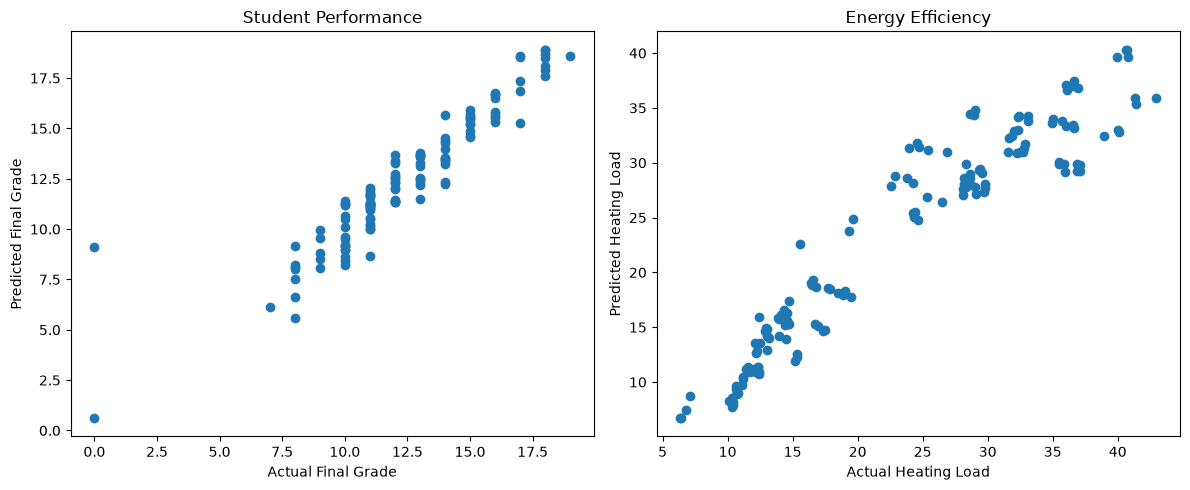

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_student_test, student_predictions)
axes[0].set_title("Student Performance")
axes[0].set_xlabel("Actual Final Grade")
axes[0].set_ylabel("Predicted Final Grade")

axes[1].scatter(y_energy_test, energy_predictions)
axes[1].set_title("Energy Efficiency")
axes[1].set_xlabel("Actual Heating Load")
axes[1].set_ylabel("Predicted Heating Load")

plt.tight_layout()
plt.show()

In [14]:
import gradio as gr

def predict_student_gradio(studytime, failures, absences, G1, G2):
    input_data = pd.DataFrame(
        [[studytime, failures, absences, G1, G2]],
        columns=student_input_columns
    )

    prediction = student_model.predict(input_data)[0]

    return f"Predicted Final Grade (G3): {prediction:.2f} / 20"

In [15]:
student_demo = gr.Interface(
    fn=predict_student_gradio,
    inputs=[
        gr.Number(label="Weekly Study Time (1-4)", value=2),
        gr.Number(label="Past Failures", value=0),
        gr.Number(label="Absences", value=4),
        gr.Number(label="First Period Grade (G1)", value=10),
        gr.Number(label="Second Period Grade (G2)", value=11)
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Student Final Grade Predictor",
    description="Enter student information to estimate the final grade."
)

student_demo.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset3.csv


In [16]:
def predict_energy_gradio(X1, X2, X3, X4, X5, X6, X7, X8):
    input_data = pd.DataFrame(
        [[X1, X2, X3, X4, X5, X6, X7, X8]],
        columns=energy_input_columns
    )

    prediction = energy_model.predict(input_data)[0]

    return f"Predicted Heating Load (Y1): {prediction:.2f}"

In [17]:
energy_demo = gr.Interface(
    fn=predict_energy_gradio,
    inputs=[
        gr.Number(label="X1 - Relative Compactness", value=0.8),
        gr.Number(label="X2 - Surface Area", value=600),
        gr.Number(label="X3 - Wall Area", value=300),
        gr.Number(label="X4 - Roof Area", value=200),
        gr.Number(label="X5 - Overall Height", value=3.5),
        gr.Number(label="X6 - Orientation", value=2),
        gr.Number(label="X7 - Glazing Area", value=0.2),
        gr.Number(label="X8 - Glazing Area Distribution", value=2)
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Building Heating Load Predictor",
    description="Enter building design characteristics to estimate heating load."
)

energy_demo.launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset4.csv


In [18]:
from flask import Flask, request, render_template_string
from threading import Thread
import time

app = Flask(__name__)

In [19]:
HTML_TEMPLATE = """
<!DOCTYPE html>
<html>
<head>
    <title>{{ title }}</title>
    <style>
        body {
            font-family: Arial, sans-serif;
            max-width: 750px;
            margin: 40px auto;
            padding: 20px;
            background: #f4f6f8;
        }
        .container {
            background: white;
            padding: 25px;
            border-radius: 10px;
        }
        label {
            display: block;
            margin-top: 14px;
            font-weight: bold;
        }
        input {
            width: 95%;
            padding: 9px;
            margin-top: 5px;
        }
        button {
            margin-top: 20px;
            padding: 12px 20px;
            cursor: pointer;
        }
        .result {
            margin-top: 20px;
            padding: 12px;
            background: #e8f5e9;
            border-radius: 5px;
        }
    </style>
</head>
<body>
    <div class="container">
        <h1>{{ title }}</h1>
        <p>{{ description }}</p>

        <form method="POST">
            {% for field in fields %}
                <label>{{ field.label }}</label>
                <input
                    type="number"
                    name="{{ field.name }}"
                    step="any"
                    value="{{ field.value }}"
                    required
                >
            {% endfor %}

            <button type="submit">Predict</button>
        </form>

        {% if result %}
            <div class="result">
                <strong>{{ result }}</strong>
            </div>
        {% endif %}

        <p><a href="/">Back to Home</a></p>
    </div>
</body>
</html>
"""

HOME_TEMPLATE = """
<!DOCTYPE html>
<html>
<head><title>Linear Regression Project</title></head>
<body style="font-family:Arial; margin:40px;">
    <h1>Linear Regression Prediction System</h1>
    <p>Select a model to make a prediction.</p>
    <ul>
        <li><a href="/student">Student Final Grade Predictor</a></li>
        <li><a href="/energy">Building Heating Load Predictor</a></li>
    </ul>
</body>
</html>
"""

print("HTML templates created successfully!")

HTML templates created successfully!


In [20]:
@app.route("/")
def home():
    return render_template_string(HOME_TEMPLATE)

In [21]:
@app.route("/student", methods=["GET", "POST"])
def student_page():
    labels = {
        "studytime": "Weekly Study Time (1-4)",
        "failures": "Past Failures",
        "absences": "Absences",
        "G1": "First Period Grade",
        "G2": "Second Period Grade"
    }

    defaults = {
        "studytime": 2,
        "failures": 0,
        "absences": 4,
        "G1": 10,
        "G2": 11
    }

    fields = [
        {
            "name": col,
            "label": labels[col],
            "value": request.form.get(col, defaults[col])
        }
        for col in student_input_columns
    ]

    result = None

    if request.method == "POST":
        try:
            values = [float(request.form[col]) for col in student_input_columns]

            if not all(np.isfinite(v) for v in values):
                raise ValueError("Inputs must be finite numbers.")

            if not 1 <= values[0] <= 4:
                raise ValueError("Study time must be between 1 and 4.")

            if not 0 <= values[1] <= 3:
                raise ValueError("Past failures must be between 0 and 3.")

            if values[2] < 0:
                raise ValueError("Absences cannot be negative.")

            if not all(0 <= v <= 20 for v in values[3:]):
                raise ValueError("Grades must be between 0 and 20.")

            input_data = pd.DataFrame(
                [values],
                columns=student_input_columns
            )

            prediction = student_model.predict(input_data)[0]
            prediction = np.clip(prediction, 0, 20)

            result = f"Predicted Final Grade (G3): {prediction:.2f} / 20"

        except ValueError as error:
            result = f"Input error: {error}"

    return render_template_string(
        HTML_TEMPLATE,
        title="Student Final Grade Predictor",
        description="Enter the student's academic information.",
        fields=fields,
        result=result
    )

In [22]:
@app.route("/energy", methods=["GET", "POST"])
def energy_page():
    labels = {
        "X1": "Relative Compactness",
        "X2": "Surface Area",
        "X3": "Wall Area",
        "X4": "Roof Area",
        "X5": "Overall Height",
        "X6": "Orientation",
        "X7": "Glazing Area",
        "X8": "Glazing Area Distribution"
    }

    defaults = {
        "X1": 0.8,
        "X2": 600,
        "X3": 300,
        "X4": 200,
        "X5": 3.5,
        "X6": 2,
        "X7": 0.2,
        "X8": 2
    }

    fields = [
        {
            "name": col,
            "label": f"{col} - {labels[col]}",
            "value": request.form.get(col, defaults[col])
        }
        for col in energy_input_columns
    ]

    result = None

    if request.method == "POST":
        try:
            values = [float(request.form[col]) for col in energy_input_columns]

            if not all(np.isfinite(v) for v in values):
                raise ValueError("Inputs must be finite numbers.")

            if not 0 < values[0] <= 1:
                raise ValueError("Relative compactness must be greater than 0 and at most 1.")

            if any(v <= 0 for v in values[1:5]):
                raise ValueError("Surface areas and height must be positive.")

            if values[5] not in [2, 3, 4, 5]:
                raise ValueError("Orientation must be 2, 3, 4, or 5.")

            if not 0 <= values[6] <= 1:
                raise ValueError("Glazing area must be between 0 and 1.")

            if values[7] not in [0, 1, 2, 3, 4, 5]:
                raise ValueError("Glazing distribution must be between 0 and 5.")

            input_data = pd.DataFrame(
                [values],
                columns=energy_input_columns
            )

            prediction = energy_model.predict(input_data)[0]

            result = f"Predicted Heating Load (Y1): {prediction:.2f}"

        except ValueError as error:
            result = f"Input error: {error}"

    return render_template_string(
        HTML_TEMPLATE,
        title="Building Heating Load Predictor",
        description="Enter the building design characteristics.",
        fields=fields,
        result=result
    )

In [23]:
def run_flask():
    app.run(
        host="127.0.0.1",
        port=5000,
        debug=False,
        use_reloader=False
    )

flask_thread = Thread(target=run_flask, daemon=True)
flask_thread.start()

time.sleep(2)

print("Open the Flask application at:")
print("http://127.0.0.1:5000")

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


Open the Flask application at:
http://127.0.0.1:5000


In [24]:
student_test_input = pd.DataFrame(
    [[2, 0, 4, 10, 11]],
    columns=student_input_columns
)

energy_test_input = pd.DataFrame(
    [[0.8, 600, 300, 200, 3.5, 2, 0.2, 2]],
    columns=energy_input_columns
)

student_result = student_model.predict(student_test_input)[0]
energy_result = energy_model.predict(energy_test_input)[0]

print(f"Student predicted final grade: {student_result:.2f} / 20")
print(f"Energy predicted heating load: {energy_result:.2f}")

Student predicted final grade: 11.22 / 20
Energy predicted heating load: 14.48


In [25]:
print(
    predict_student_gradio(2, 0, 4, 10, 11)
)

print(
    predict_energy_gradio(
        0.8, 600, 300, 200, 3.5, 2, 0.2, 2
    )
)

Predicted Final Grade (G3): 11.22 / 20
Predicted Heating Load (Y1): 14.48


In [26]:
with app.test_client() as client:

    # Test home page
    response = client.get("/")
    print("Home page:", response.status_code)

    # Test Student page
    response = client.get("/student")
    print("Student page:", response.status_code)

    # Test Student prediction
    response = client.post("/student", data={
        "studytime": "2",
        "failures": "0",
        "absences": "4",
        "G1": "10",
        "G2": "11"
    })
    print("Student prediction:", response.status_code)
    print("Student result displayed:", b"Predicted Final Grade" in response.data)

    # Test Energy page
    response = client.get("/energy")
    print("Energy page:", response.status_code)

    # Test Energy prediction
    response = client.post("/energy", data={
        "X1": "0.8",
        "X2": "600",
        "X3": "300",
        "X4": "200",
        "X5": "3.5",
        "X6": "2",
        "X7": "0.2",
        "X8": "2"
    })
    print("Energy prediction:", response.status_code)
    print("Energy result displayed:", b"Predicted Heating Load" in response.data)

Home page: 200
Student page: 200
Student prediction: 200
Student result displayed: True
Energy page: 200
Energy prediction: 200
Energy result displayed: True


In [27]:
results_table = pd.DataFrame({
    "Dataset": [
        "Student Performance",
        "Energy Efficiency"
    ],
    "Algorithm": [
        "Linear Regression",
        "Linear Regression"
    ],
    "Target": [
        "G3 - Final Grade",
        "Y1 - Heating Load"
    ],
    "MAE": [
        mean_absolute_error(y_student_test, student_predictions),
        mean_absolute_error(y_energy_test, energy_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_student_test, student_predictions)),
        np.sqrt(mean_squared_error(y_energy_test, energy_predictions))
    ],
    "R2 Score": [
        r2_score(y_student_test, student_predictions),
        r2_score(y_energy_test, energy_predictions)
    ]
})

display(results_table.round(3))

,Dataset,Algorithm,Target,MAE,RMSE,R2 Score
0,Student Performance,Linear Regression,G3 - Final Grade,0.746,1.155,0.863
1,Energy Efficiency,Linear Regression,Y1 - Heating Load,2.182,3.025,0.912
